# Check Real-Valued PCN

This notebook is a small sanity check for the plain real-valued predictive coding network in `qvnn_pc.models.pcn`.
It uses one of the benchmark functions, trains for a few epochs, and inspects both regression metrics and inference dynamics.

In [9]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
repo_root = next(path for path in candidates if (path / "src" / "qvnn_pc").exists())
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

torch.set_printoptions(precision=4, sci_mode=True)
torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [10]:
from qvnn_pc.data import make_benchmark_regression_split
from qvnn_pc.models.pcn import PredictiveCodingNetwork

function_name = "ackley"
n = 30_000
sample_seed = 1
split_seed = 2

split = make_benchmark_regression_split(
    function_name,
    n=n,
    sample_seed=sample_seed,
    split_seed=split_seed,
    device=None,
)

# The benchmark split is quaternion-shaped for the quaternion models.
# For the plain PCN we use the real standardized inputs and scalar targets.
x_train = split.x_train[:, 0, :].to(device)
x_val = split.x_val[:, 0, :].to(device)
x_test = split.x_test[:, 0, :].to(device)

y_train = split.y_train_scalar.unsqueeze(-1).to(device)
y_val = split.y_val_scalar.unsqueeze(-1).to(device)
y_test = split.y_test_scalar.unsqueeze(-1).to(device)

x_train.shape, y_train.shape

(torch.Size([21000, 4]), torch.Size([21000, 1]))

In [25]:
pcn = PredictiveCodingNetwork(
    dims=[4, 20, 20, 20, 20],
    output_dim=1,
    activation="tanh",
    prediction_inference_steps=32,
    prediction_eta_infer=0.05,
    device=device,
)

pcn

PredictiveCodingNetwork(
  (layers): ModuleList(
    (0-3): 4 x PCNLayer()
  )
  (readout): Linear(in_features=20, out_features=1, bias=False)
)

In [26]:
probe_x = x_train[:8]
probe_y = y_train[:8]

probe_result = pcn.infer_latents(
    probe_x,
    y=probe_y,
    steps=8,
    eta_infer=0.05,
    return_trace=True,
)

probe_result["prediction"].shape, probe_result["trace"].keys()

(torch.Size([8, 1]),
 dict_keys(['free_energy', 'reconstruction_mse', 'supervised_mse', 'mean_latent_grad_norm']))

In [27]:
history = pcn.fit(
    x_train,
    y_train,
    x_val=x_val,
    y_val=y_val,
    epochs=100,
    batch_size=512,
    shuffle_generator=torch.Generator(device="cpu").manual_seed(1234),
    eta_infer=0.05,
    eta_learn=0.001,
    T_infer=50,
    T_learn=500,
    eval_infer_steps=32,
    latent_init="feedforward",
)

history["runtime"], history["epochs_ran"]

Training PCN:   5%|▌         | 5/100 [01:06<21:08, 13.35s/epoch]


KeyboardInterrupt: 

In [28]:
train_metrics = pcn.evaluate(x_train, y_train, infer_steps=32, eta_infer=0.05)
val_metrics = pcn.evaluate(x_val, y_val, infer_steps=32, eta_infer=0.05)
test_metrics = pcn.evaluate(x_test, y_test, infer_steps=32, eta_infer=0.05, return_trace=True)

pd.DataFrame(
    [train_metrics, val_metrics, {k: v for k, v in test_metrics.items() if k != "inference_trace"}],
    index=["train", "val", "test"],
)

,free_energy,reconstruction_mse,supervised_mse,mse,mae,mape,r2
train,214.254562,0.022628,428.486511,428.486328,20.666536,1.000016,-336.752197
val,213.923828,0.022476,427.825165,427.824615,20.647285,0.999944,-307.121185
test,213.501709,0.022385,426.981018,426.980896,20.623133,1.000050,-272.279510


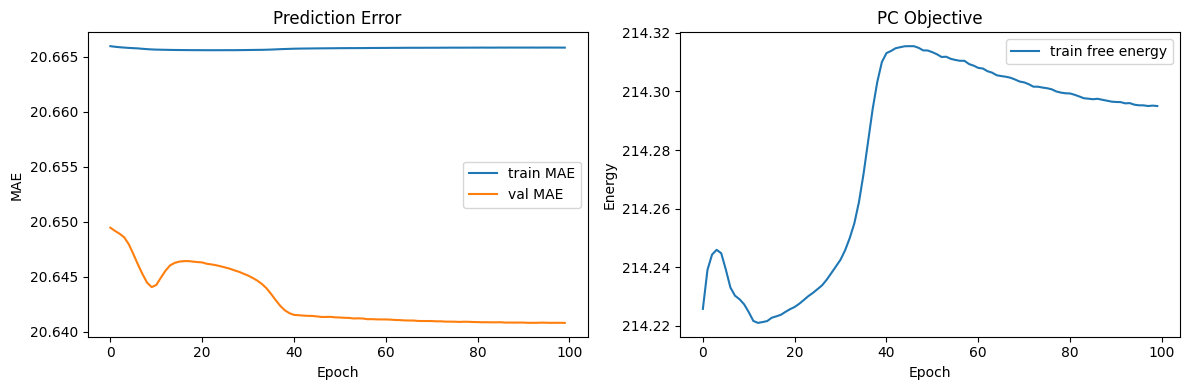

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["mae"], label="train MAE")
axes[0].plot(history["validation_mae"], label="val MAE")
axes[0].set_title("Prediction Error")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MAE")
axes[0].legend()

axes[1].plot(history["free_energy"], label="train free energy")
axes[1].set_title("PC Objective")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Energy")
axes[1].legend()

plt.tight_layout()
plt.show()

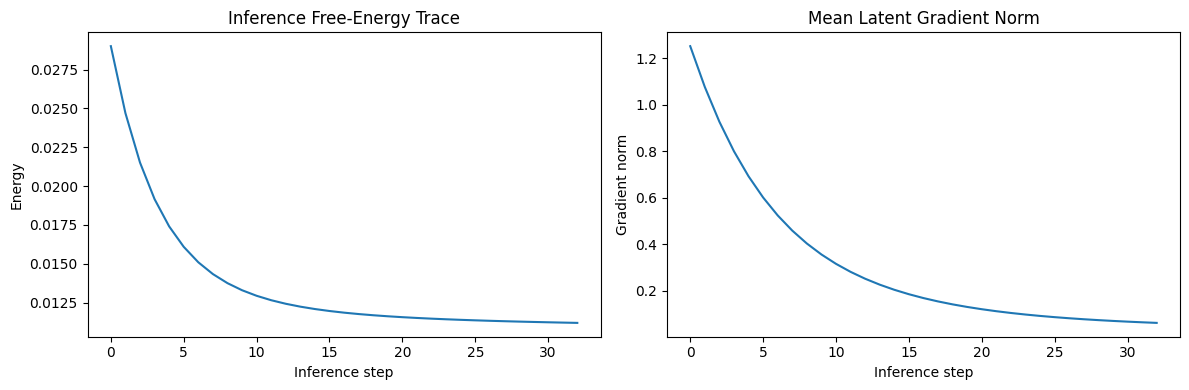

In [30]:
trace = test_metrics["inference_trace"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(trace["free_energy"])
axes[0].set_title("Inference Free-Energy Trace")
axes[0].set_xlabel("Inference step")
axes[0].set_ylabel("Energy")

axes[1].plot(trace["mean_latent_grad_norm"])
axes[1].set_title("Mean Latent Gradient Norm")
axes[1].set_xlabel("Inference step")
axes[1].set_ylabel("Gradient norm")

plt.tight_layout()
plt.show()

In [31]:
pred = pcn.predict(x_test[:10], infer_steps=32, eta_infer=0.05)
pd.DataFrame(
    {
        "target": y_test[:10, 0].detach().cpu(),
        "prediction": pred[:10, 0].detach().cpu(),
    }
)

/home/lukas/src/Sem4/OML/oml_fs2026/PCQVNN/.venv/lib/python3.12/site-packages/pandas/io/formats/format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,target,prediction
0,20.659164,-0.305908
1,21.412739,-0.229126
2,21.266457,0.019669
3,21.805386,0.781738
4,21.448284,-0.293701
5,20.572575,-0.200073
6,20.502354,0.052002
7,21.274792,-0.285156
8,21.007122,-0.336182
9,21.308746,0.207275
